# Example Noise Simulation

Using the NoiseSim class to create noisy magnetometer measurements

By: Catelin Smith

#### import relevant classes

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np

from noise_sim import NoiseSim
from TD_noise_sim import TDNoiseSim

sim = NoiseSim()

### 1) Test Basic Functions

In [2]:
# make a scaling matrix

ksi = [0, 0, 0]
rho = 0
lamb = 0
phi = 0
eps = [0, 0, 0]
D_si = np.eye(3)

sim.set_scaling_matrix(ksi, rho, lamb, phi, eps, D_si)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [3]:
# make a bias vector

sim.set_bias(np.zeros(3))

array([0., 0., 0.])

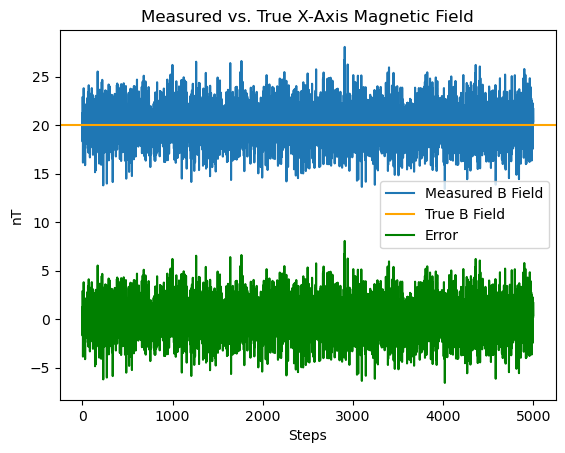

In [4]:
# plot a basic example magnetic field w/ only gaussian noise
np.random.seed()

H = np.array([20.0, -10.0, 15.0]) # nT
A = np.eye(3) # attitude matrix
sigma = 2.0

meas_base, err_base = sim.basic_mag_error(A, H, sigma, n=5000)

plt.plot(meas_base[:, 0], label="Measured B Field")
plt.axhline(H[0], label="True B Field", c="orange")
plt.plot(err_base[:, 0], label="Error",c="green")
plt.legend()
plt.xlabel("Steps")
plt.ylabel("nT")
plt.title("Measured vs. True X-Axis Magnetic Field")
plt.show()

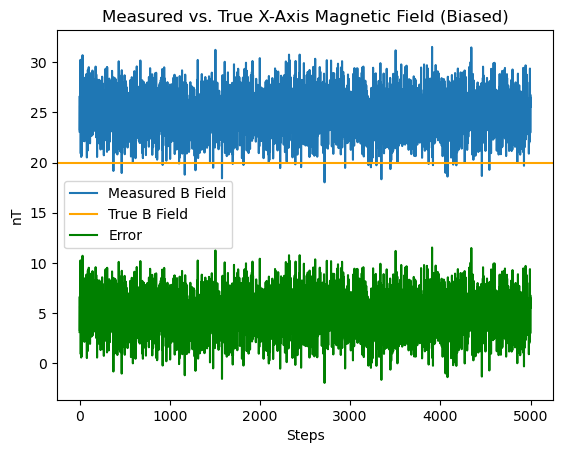

In [5]:
# bias the field, then replot

sim.set_bias(np.array([5.0, -2.0, 10.0]))

meas_bias, err_bias = sim.basic_mag_error(A, H, sigma, n=5000)

plt.plot(meas_bias[:, 0], label="Measured B Field")
plt.axhline(H[0], label="True B Field", c="orange")
plt.plot(err_bias[:, 0], label="Error",c="green")
plt.legend()
plt.xlabel("Steps")
plt.ylabel("nT")
plt.title("Measured vs. True X-Axis Magnetic Field (Biased)")
plt.show()

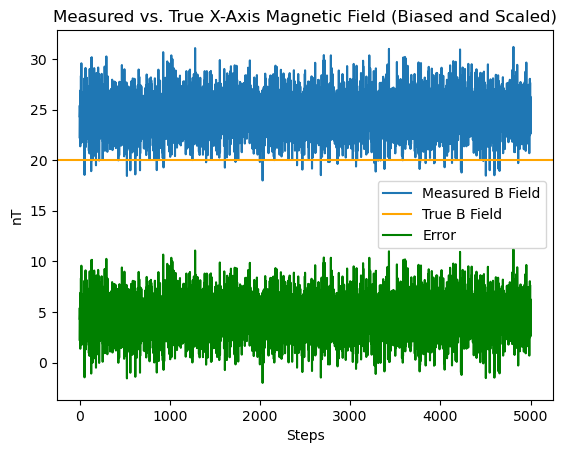

In [6]:
# Add in scaling matrix, then replot

D_full = sim.set_scaling_matrix(
    ksi  = [0.02, -0.01, 0.015],
    rho  = np.deg2rad(0),
    lamb = np.deg2rad(0),
    phi  = np.deg2rad(0),
    eps  = [np.deg2rad(0), np.deg2rad(0), np.deg2rad(0)],
    D_si = np.eye(3)
)

meas_full, err_full = sim.basic_mag_error(A, H, sigma, n=5000)

plt.plot(meas_full[:, 0], label="Measured B Field")
plt.axhline(H[0], label="True B Field", c="orange")
plt.plot(err_full[:, 0], label="Error",c="green")
plt.legend()
plt.xlabel("Steps")
plt.ylabel("nT")
plt.title("Measured vs. True X-Axis Magnetic Field (Biased and Scaled)")
plt.show()

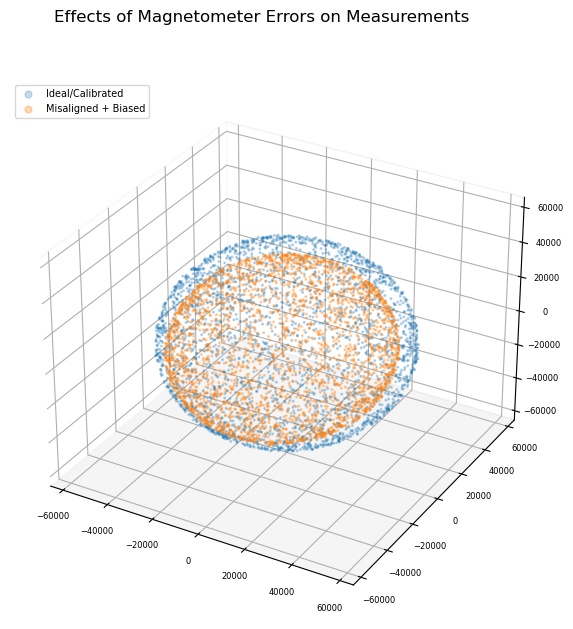

In [7]:
np.random.seed(42)
H      = np.array([20000., 5000., 45000.])
sigma  = 300.0           
b_bias   = sim.set_bias(np.array([1000., -5000., 0.]))
D_scaled = sim.set_scaling_matrix([0, 0, 0], 0, 0, 0, [0,.0,.5], [[1.05, .01, -0.05], [.01, .98, .03], [-0.05, 0.03, 1.05]])


sim.plot_sphere(H, sigma, n=3000)

### 2) Test Time-Series Noise Simulation

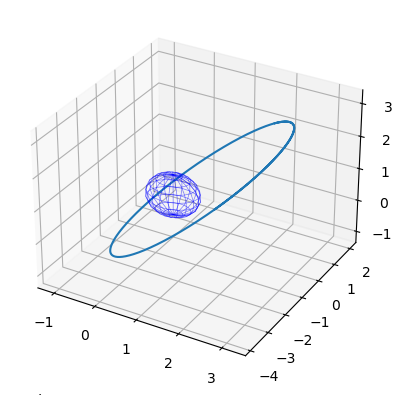

In [8]:
td_noise_sim = TDNoiseSim(sim=sim)
td_noise_sim.set_bias(np.array([5.0, -2.0, 10.0]))

from orbit import Orbit
import random

# create a basic earth orbit

orbit_sim1 = Orbit("Earth")
r = orbit_sim1.dynamics.R
ax = plt.axes(projection='3d')

r0 = [r + random.uniform(1, 3) * r, 
      r + random.uniform(1, 3) * r, 
      r + random.uniform(1, 3) * r]
    
theta = random.uniform(0, 2 * math.pi)
phi = random.uniform(0, 2 * math.pi)
t = np.linspace(0, 85000, 5000)
    
sol = orbit_sim1.run(r0, theta, phi, t)
A = orbit_sim1.get_attitude(sol)

x = sol[:, 0] / r
y = sol[:, 1] / r
z = sol[:, 2] / r

plt.plot(sol[:, 0], sol[:, 1], sol[:, 2])
        
# Earth
u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
ax.plot_wireframe(r*np.cos(u)*np.sin(v),r*np.sin(u)*np.sin(v),
                  r*np.cos(v),color="b",alpha=0.5,lw=0.5,zorder=0)
        
plt.show()

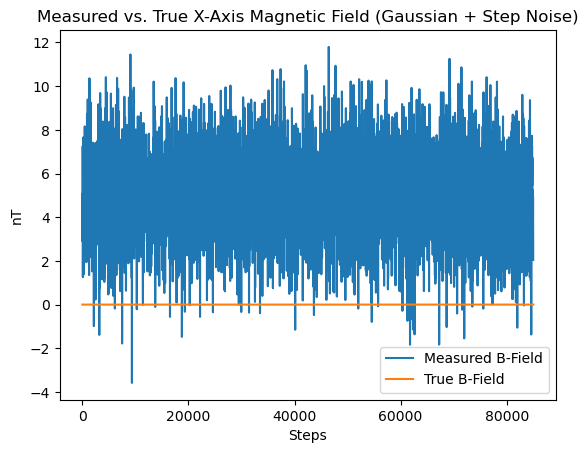

In [9]:
N  = 5000

H_series = np.zeros((N, 3))

D = [[0, 0, 0], 0, 0, 0, [0,.0,.5], [[1.05, .01, -0.05], [.01, .98, .03], [-0.05, 0.03, 1.05]]]

H = np.array([0, 0, 0])

sigma = 2.0

# make basic magnetic field
for i in range(N):
    H_series[i, 0] = H[0]
    H_series[i, 1] = H[1]
    H_series[i, 2] = H[2]
    
    
# test simulate_orbit (should see Gaussian noise and step noise from MTQ)
G = np.array([[10., 0., 0.],
             [0., 10., 0.],
             [0., 0., 10.]])

S = np.array([[1e-4, 1e-2],
             [1e-4, 1e-2],
             [1e-4, 1e-2]])

mtq = np.array([0., 0., 0.5])

td_sim, true_B = td_noise_sim.simulate_orbit(A, H_series, G, S, mtq, sigma, N)

plt.plot(t, td_sim[:, 0], label="Measured B-Field")
plt.plot(t, true_B[:, 0], label="True B-Field")
plt.title("Measured vs. True X-Axis Magnetic Field (Gaussian + Step Noise)")
plt.legend()
plt.xlabel("Steps")
plt.ylabel("nT")
plt.show()

In [10]:
# create more accurate, complex magnetic field to measure from

from geopack import geopack, t96

np.random.seed(42)
N  = 5000
fs = 25.0       # sample rate (Hz)
sigma = 2.0    # Gaussian noise std dev (nT)
t = np.linspace(0, 85000, 5000)

ut = 100
xgsm = -5.1
ygsm = 0.3
zgsm = 2.8

par = [1., -10., 2., -5., 0., 0., 0, xgsm,ygsm,zgsm]

H_series = np.zeros((N, 3))

for i in range(N):
    ps = geopack.recalc(ut)
    bxgsm,bygsm,bzgsm = t96.t96(par, ps, x[i], y[i], z[i])
    
    H_series[i, 0] = bxgsm
    H_series[i, 1] = bygsm
    H_series[i, 2] = bzgsm
    
    ut = ut + 17

Load IGRF coefficients ...


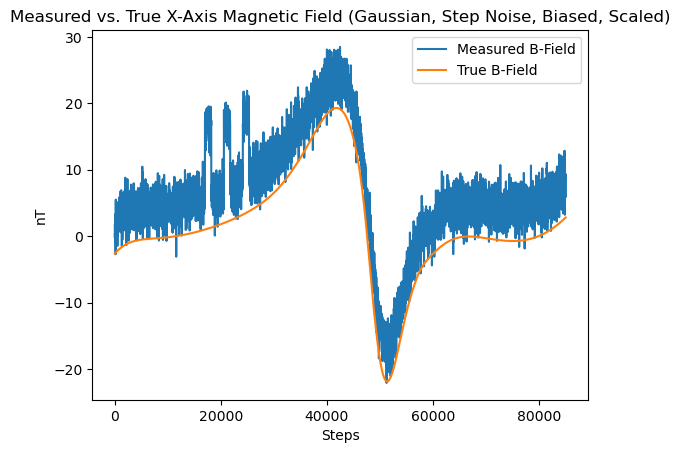

[ 5. -2. 10.]


In [19]:
new_sim = TDNoiseSim(sim=sim)
new_sim.set_bias(np.array([5.0, -2.0, 10.0]))


D = [[0.01, -0.005, 0.008], np.deg2rad(1), np.deg2rad(0.8),
                    np.deg2rad(0.9), [np.deg2rad(0.5)]*3, np.eye(3)]

G = np.array([[1., 0., 0.],
             [0., 1., 0.],
             [0., 0., 1.]])

S = np.array([[1e-4, 1e-3],
             [1e-4, 1e-3],
             [1e-4, 1e-3]])

mtq = np.array([10, 10, -20])

new_sim.set_scaling_matrix(D[0],D[1], D[2],D[3], D[4], D[5])

X, true_B= new_sim.simulate_orbit(A=A, H=H_series, G=G, S=S, mtq=mtq, sigma=2.0, n=N)

plt.plot(t, X[:, 0], label="Measured B-Field")
plt.plot(t, true_B[:, 0], label="True B-Field")
plt.title("Measured vs. True X-Axis Magnetic Field (Gaussian, Step Noise, Biased, Scaled)")
plt.legend()
plt.xlabel("Steps")
plt.ylabel("nT")
plt.show()

print(new_sim.bias)

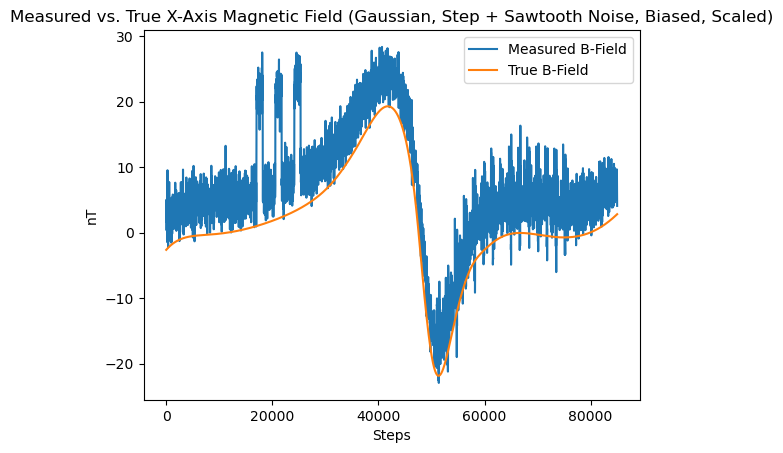

In [18]:
N  = 5000
fs = 25.0       # sample rate (Hz)
sigma = 2.0    # Gaussian noise std dev (nT)
t = np.linspace(0, 85000, 5000)

scale1 = [[0.01, -0.005, 0.008], np.deg2rad(1), np.deg2rad(0.8),
                    np.deg2rad(0.9), [np.deg2rad(0.5)]*3, np.eye(3)]
b1 = np.array([5.0, -2.0, 10.0])


mtq1 = np.array([[0.9, 0.05, 0.2], [-7., 7., 10.]])
X1, true_B = new_sim.simulate_orbit_2(A=A, H=H_series, scale=scale1, b=b1, mtq=mtq1, sigma=sigma, n=N, fs=fs)

plt.plot(t, X1[:, 0], label="Measured B-Field")
plt.plot(t, true_B[:, 0], label="True B-Field")
plt.title("Measured vs. True X-Axis Magnetic Field (Gaussian, Step + Sawtooth Noise, Biased, Scaled)")
plt.legend()
plt.xlabel("Steps")
plt.ylabel("nT")
plt.show()